Training in progress...
Epoch 1 complete.
Epoch 2 complete.
Testing the model...
Test Accuracy on 10,000 unseen images: 98.67%


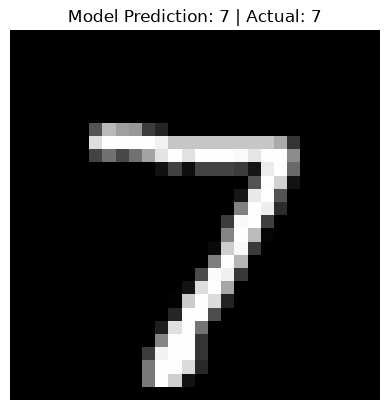

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 1. The Data
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# 2. The CNN Architecture
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__() # Fixed: added ()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1) # Fixed: Conv2d
        self.pool = nn.MaxPool2d(2, 2) # Fixed: MaxPool2d
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # Fixed: Conv2d
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x))) # Fixed: torch.relu
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7) # Fixed: Flatten before linear layer
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = CNN()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
epochs = 2

# 3. Training Loop
print("Training in progress...")
for epoch in range(epochs): # Fixed: range(epochs)
    for images, labels in train_loader: # Fixed: used train_loader
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch+1} complete.")

# 4. TESTING & PLOTTING
print("Testing the model...")
correct = 0
total = 0

# We use torch.no_grad() because we are testing, not training
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy on 10,000 unseen images: {100 * correct / total:.2f}%")

# 5. Grab one image to visualize
data_iter = iter(test_loader)
images, labels = next(data_iter) # Fixed: get the batch

# Make a prediction on the first image
with torch.no_grad():
    output = model(images[0].unsqueeze(0)) # Fixed: add batch dimension
    _, predicted = torch.max(output, 1)

# Show it
plt.imshow(images[0].squeeze(), cmap='gray')
plt.title(f"Model Prediction: {predicted.item()} | Actual: {labels[0].item()}")
plt.axis('off')
plt.show()